# Energy integrals — braking energy and full-throttle time (T1/T4 inputs)

No real per-lap ERS telemetry exists (F-13): these integrals estimate the raw
material of the 2026 energy game from what the car observably did. Braking energy is
the kinetic energy shed across each brake application (an upper bound on what an
MGU-K could harvest — T4 applies the conversion); full-throttle time is where
deployment happens (T1). Telemetry runs at roughly 4–5 Hz and unevenly (AR-16), so
every integral rides the actual timestamp deltas, and nothing integrates across a
trace break — a dropout would otherwise donate invented energy to the lap.

The full per-circuit medians live in `configs/physics_params.yaml`; this notebook
shows the per-lap distributions behind them for two contrasting circuits and the
cadence evidence.

In [1]:
import pandas as pd

from senna import config
from senna.data.db import database_url, engine_for
from senna.physics.fits import frames, plots
from senna.physics.fits.gate import assert_quality_reports

fits_cfg = config.load("fits")
ingest_cfg = config.load("ingest")
CALIB = config.get(config.load("data_split"), "calibration_rounds")
SLICKS = ("SOFT", "MEDIUM", "HARD")

assert_quality_reports(
    config.get(ingest_cfg, "seasons"),
    config.REPO_ROOT / config.get(ingest_cfg, "quality.report_dir"),
)
engine = engine_for(database_url())
conn = await engine.connect()
index = await frames.circuit_index(conn, CALIB)
index[["slug", "era"]].drop_duplicates().groupby("era").size()

era
2024    25
2026     6
dtype: int64

In [2]:
import yaml

params = yaml.safe_load(open(config.REPO_ROOT / "configs" / "physics_params.yaml"))
energy_rows = []
for slug, circuit in params["circuits"].items():
    for era, values in (circuit.get("energy") or {}).items():
        energy_rows.append({"circuit": slug, "era": era, **values})
pd.DataFrame(energy_rows)

,circuit,era,braking_energy_mj_per_lap,full_throttle_frac,full_throttle_s_per_lap,median_cadence_hz,n_laps
0,abu_dhabi_grand_prix,2024,11.0475,0.5212,46.8595,4.1667,3028
1,australian_grand_prix,2024,8.9175,0.6168,51.0000,4.1667,852
2,australian_grand_prix,2026,7.7181,0.5433,45.9990,4.1667,834
3,austrian_grand_prix,2024,9.5080,0.5700,40.2220,4.1667,995
4,azerbaijan_grand_prix,2024,14.8380,0.5299,56.9785,4.1667,1649
5,bahrain_grand_prix,2024,13.1607,0.4791,46.8597,4.1667,1958
6,belgian_grand_prix,2024,11.2084,0.5982,65.3225,4.1667,734
7,british_grand_prix,2024,8.1486,0.5765,53.5400,4.1667,802
8,canadian_grand_prix,2026,9.7750,0.5320,41.1205,4.1667,935
9,chinese_grand_prix,2024,11.3091,0.4496,44.7210,4.1667,1689


In [3]:
from senna.data import fastf1_loader
from senna.physics.fits.energy import session_energy_frame

fastf1_loader.enable_cache(config.REPO_ROOT / config.get(ingest_cfg, "fastf1.cache_dir"))
GAP_SPLIT_S = config.get(ingest_cfg, "cleaning.telemetry_gap_split_s")
THROTTLE_FULL = config.get(fits_cfg, "energy.throttle_full_pct")
SC_BURN = config.get(fits_cfg, "fuel.sc_burn_factor")

per_lap = {}
for slug in ("monaco_grand_prix", "italian_grand_prix"):
    row = index.query("slug == @slug and era == '2024' and session_name == 'Race'").iloc[-1]
    season, round_number = int(row["season"]), int(row["round"])
    car_data, session_laps = fastf1_loader.load_car_data(season, round_number, "Race")
    physics = config.load("physics_2024")
    per_lap[slug] = session_energy_frame(
        car_data,
        session_laps,
        gap_split_s=GAP_SPLIT_S,
        throttle_full_pct=THROTTLE_FULL,
        car_mass_kg=config.get(physics, "mass.minimum_car_kg"),
        race_fuel_kg=config.get(physics, "mass.race_fuel_kg"),
        sc_burn_factor=SC_BURN,
    )
    print(slug, row["season"], f"{len(per_lap[slug])} laps integrated")

core           INFO 	Loading data for Monaco Grand Prix - Race [v3.8.3]


req            INFO 	Using cached data for session_info


req            INFO 	Using cached data for driver_info


req            INFO 	Using cached data for session_status_data


req            INFO 	Using cached data for lap_count


req            INFO 	Using cached data for track_status_data


... (17 outputs left out)

req            INFO 	Using cached data for car_data


req            INFO 	Using cached data for position_data


core           INFO 	Finished loading data for 20 drivers: ['1', '4', '81', '16', '63', '44', '23', '5', '12', '6', '55', '87', '22', '30', '31', '10', '43', '18', '14', '27']


italian_grand_prix 2025 897 laps integrated


/Users/saad/senna/docs/fits/energy/per_lap_distributions.png


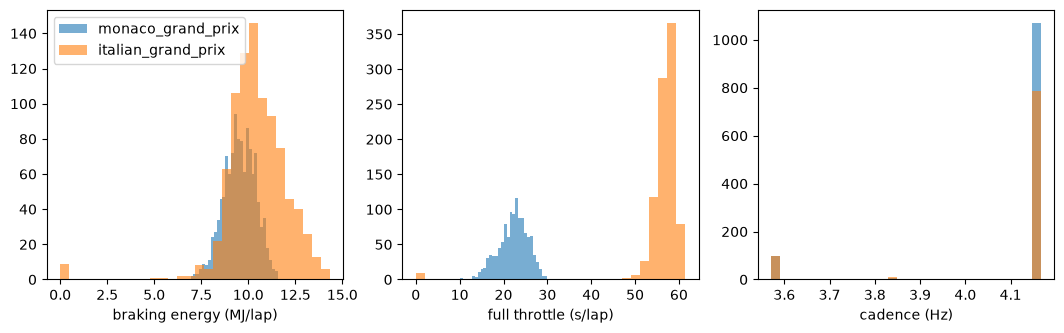

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for slug, frame in per_lap.items():
    axes[0].hist(frame["braking_energy_mj"], bins=30, alpha=0.6, label=slug)
    axes[1].hist(frame["full_throttle_s"], bins=30, alpha=0.6, label=slug)
    axes[2].hist(frame["cadence_hz"], bins=30, alpha=0.6, label=slug)
labels = ["braking energy (MJ/lap)", "full throttle (s/lap)", "cadence (Hz)"]
for ax, label in zip(axes, labels, strict=True):
    ax.set_xlabel(label)
axes[0].legend()
print(plots.save_figure(fig, "energy", "per_lap_distributions"))

Monaco sheds less energy per braking event but brakes constantly; Monza's few stops
come from 340 km/h. The cadence histogram is the AR-16 evidence: samples arrive at
roughly 4–5 Hz, nowhere near the 10 Hz v2 assumed — assuming a fixed 0.25 s step
would misprice every integral.

In [5]:
await conn.close()
await engine.dispose()